In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:\\Users\\HP\\OneDrive\\文档\\GitHub\\internship\\week_9\\House_Price_Prediction\\data\\house_prices.csv")

df.head()

,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price
0,PROP0001,3712,4,3,36,Rural,House,22260000
1,PROP0002,1591,4,1,35,Suburb,House,16057500
2,PROP0003,1646,4,3,20,Rural,Villa,12730000
3,PROP0004,4814,1,2,13,City Center,Villa,50840000
4,PROP0005,800,4,2,38,Suburb,Apartment,10650000


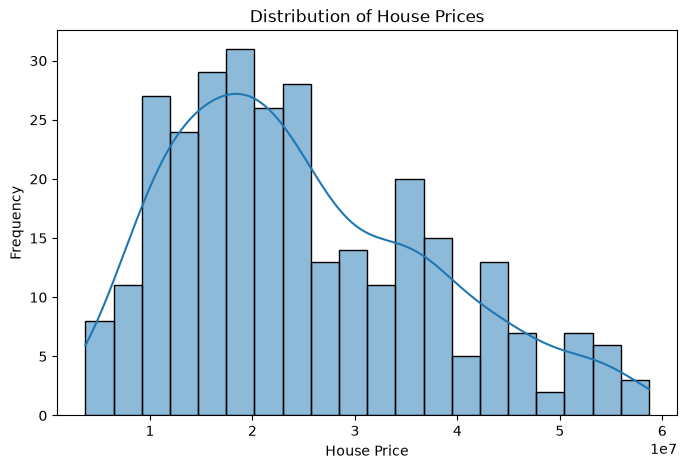

In [54]:
plt.figure(figsize = (8,5))

sns.histplot(df["Price"], bins = 20, kde = True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

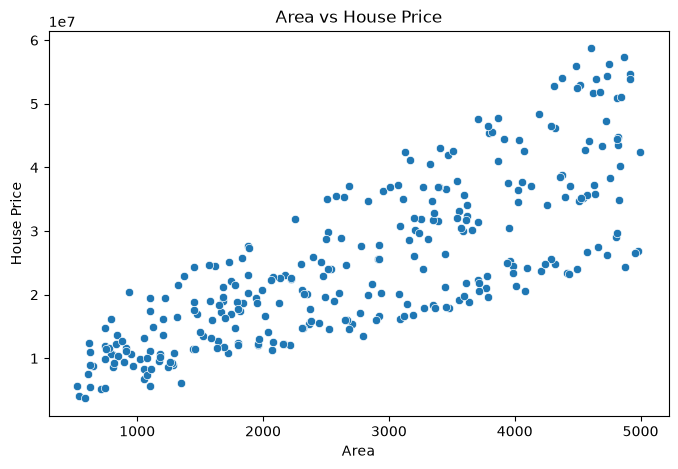

In [55]:
plt.figure(figsize = (8,5))

sns.scatterplot(data = df, x = "Area", y = "Price")

plt.title("Area vs House Price")
plt.xlabel("Area")
plt.ylabel("House Price")

plt.show()

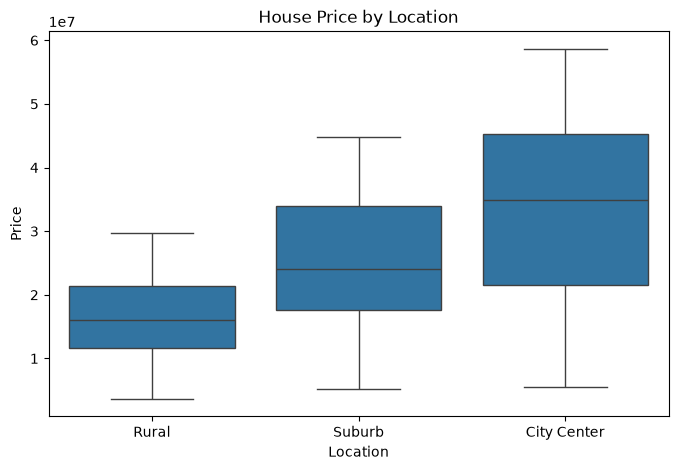

In [56]:
plt.figure(figsize = (8,5))

sns.boxplot(data = df, x = "Location", y = "Price")

plt.title("House Price by Location")
plt.show()

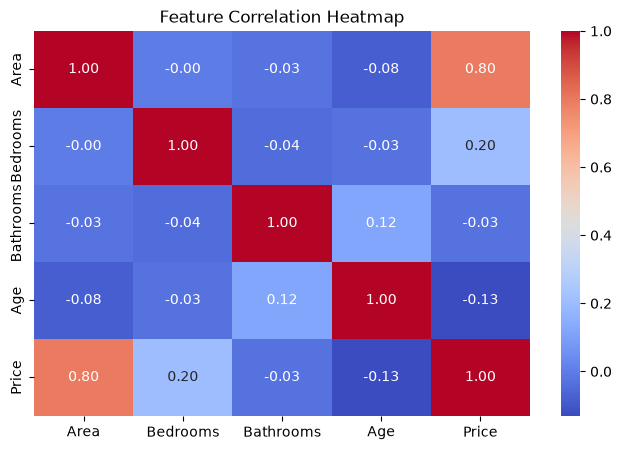

In [57]:
plt.figure(figsize = (8,5))

sns.heatmap(
    df.select_dtypes(include = "number").corr(),
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [58]:
print(df.columns)

print(df.dtypes)

df.info()

Index(['Property_ID', 'Area', 'Bedrooms', 'Bathrooms', 'Age', 'Location',
       'Property_Type', 'Price'],
      dtype='str')
Property_ID        str
Area             int64
Bedrooms         int64
Bathrooms        int64
Age              int64
Location           str
Property_Type      str
Price            int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Property_ID    300 non-null    str  
 1   Area           300 non-null    int64
 2   Bedrooms       300 non-null    int64
 3   Bathrooms      300 non-null    int64
 4   Age            300 non-null    int64
 5   Location       300 non-null    str  
 6   Property_Type  300 non-null    str  
 7   Price          300 non-null    int64
dtypes: int64(5), str(3)
memory usage: 18.9 KB


In [59]:
x = df.drop(columns = ["Property_ID", "Price"])

y = df["Price"]

print("Features shape : ", x.shape)

print("target shape : ", y.shape)

Features shape :  (300, 6)
target shape :  (300,)


In [60]:
print(df.isnull().sum())

Property_ID      0
Area             0
Bedrooms         0
Bathrooms        0
Age              0
Location         0
Property_Type    0
Price            0
dtype: int64


In [61]:
print("Duplicated rows :: ", df.duplicated().sum())

Duplicated rows ::  0


In [62]:
x_encoded = pd.get_dummies(
    x,
    columns = ["Location", "Property_Type"],
    dtype = int
)

x_encoded.head()

,Area,Bedrooms,Bathrooms,Age,Location_City Center,Location_Rural,Location_Suburb,Property_Type_Apartment,Property_Type_House,Property_Type_Villa
0,3712,4,3,36,0,1,0,0,1,0
1,1591,4,1,35,0,0,1,0,1,0
2,1646,4,3,20,0,1,0,0,0,1
3,4814,1,2,13,1,0,0,0,0,1
4,800,4,2,38,0,0,1,1,0,0


In [63]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x_encoded,
    y,
    test_size = 0.2,
    random_state = 42    #reproducible split
)

print("Training features :: ", x_train.shape)
print("Testing features :: ", x_test.shape)
print("Training target :: ", y_train.shape)
print("Testing target :: ", y_test.shape)

Training features ::  (240, 10)
Testing features ::  (60, 10)
Training target ::  (240,)
Testing target ::  (60,)


In [64]:
print(x_encoded.columns.tolist())
print(x_encoded.shape)
print(x_encoded.head().to_string())

['Area', 'Bedrooms', 'Bathrooms', 'Age', 'Location_City Center', 'Location_Rural', 'Location_Suburb', 'Property_Type_Apartment', 'Property_Type_House', 'Property_Type_Villa']
(300, 10)
   Area  Bedrooms  Bathrooms  Age  Location_City Center  Location_Rural  Location_Suburb  Property_Type_Apartment  Property_Type_House  Property_Type_Villa
0  3712         4          3   36                     0               1                0                        0                    1                    0
1  1591         4          1   35                     0               0                1                        0                    1                    0
2  1646         4          3   20                     0               1                0                        0                    0                    1
3  4814         1          2   13                     1               0                0                        0                    0                    1
4   800         4          2   38  

In [65]:
import numpy as np

x = x_train["Area"].to_numpy()
y = y_train.to_numpy()

print("Area :: ", x[:5])
print("Price :: ", y[:5])

Area ::  [3511 3911 2705 3539  814]
Price ::  [42610000 44410000 15375000 32017500  9255000]


In [66]:
x_mean = np.mean(x)
y_mean = np.mean(y)

print("Average Area :: ", x_mean)
print("Average Price :: ", y_mean)

Average Area ::  2762.2166666666667
Average Price ::  24954010.416666668


In [67]:
numerator = np.sum((x - x_mean) * (y - y_mean))

denominator = np.sum((x - x_mean) ** 2)

m = numerator / denominator

print("Slope :: ", m)

Slope ::  7889.31495636646


In [68]:
c = y_mean - (m * x_mean)

print("Intercept :: ", c)

Intercept ::  3162013.155608624


In [69]:
X_test = x_test["Area"].to_numpy()

predictions = (m * X_test)

print("First 10 predictions :: ")

for i in range(10):
    print(
        f"Actual :: {y_test.iloc[i]} | "
        f"Predicted :: {predictions[i]:.2f}"
    )

First 10 predictions :: 
Actual :: 8930000 | Predicted :: 4915043.22
Actual :: 18085000 | Predicted :: 27273361.80
Actual :: 53980000 | Predicted :: 34539420.88
Actual :: 24800000 | Predicted :: 18145424.40
Actual :: 21615000 | Predicted :: 22579219.41
Actual :: 31850000 | Predicted :: 17790405.23
Actual :: 18850000 | Predicted :: 14161320.35
Actual :: 41170000 | Predicted :: 24985460.47
Actual :: 24790000 | Predicted :: 34066061.98
Actual :: 30172500 | Predicted :: 28898560.69


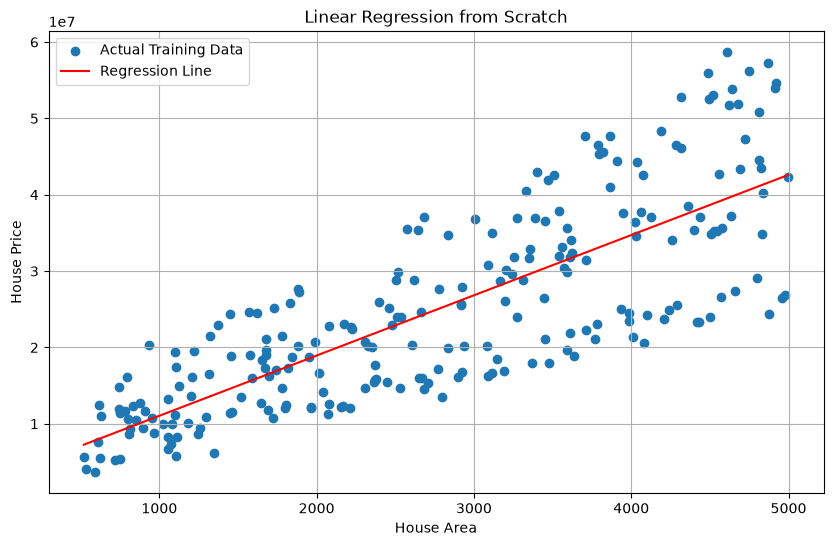

In [70]:
import matplotlib.pyplot as plt

sorted_indices = np.argsort(x)

plt.figure(figsize = (10,6))

plt.scatter(x, y, label = "Actual Training Data")

plt.plot(
    x[sorted_indices],
    (m * x[sorted_indices]) + c,
    color = "red",
    label = "Regression Line"
)

plt.xlabel("House Area")
plt.ylabel("House Price")
plt.title("Linear Regression from Scratch")

plt.legend()
plt.grid(True)

plt.savefig(
    "regression_line.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()

# Day 4: Linear Regression Using Scikit-learn

In [71]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [72]:
model.fit(x_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [73]:
y_pred = model.predict(x_test)

print("predictions generated successfully!")

for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(f"Actual :: {actual} | Predicted :: {predicted:.2f}")

predictions generated successfully!
Actual :: 8930000 | Predicted :: 15074813.48
Actual :: 18085000 | Predicted :: 19163670.53
Actual :: 53980000 | Predicted :: 49321254.81
Actual :: 24800000 | Predicted :: 27009190.40
Actual :: 21615000 | Predicted :: 21543273.97
Actual :: 31850000 | Predicted :: 32901439.82
Actual :: 18850000 | Predicted :: 22751710.13
Actual :: 41170000 | Predicted :: 39288466.86
Actual :: 24790000 | Predicted :: 29201113.12
Actual :: 30172500 | Predicted :: 30099857.48


In [74]:
print("Intercept :: ", model.intercept_)

print("\nFeature Coefficients :: ")

for feature, coefficient in zip(x_train.columns, model.coef_):
    print(f"{feature} :: {coefficient:.2f}")

Intercept ::  545408.2626840957

Feature Coefficients :: 
Area :: 7558.96
Bedrooms :: 1585708.74
Bathrooms :: 454594.04
Age :: -82443.68
Location_City Center :: 8453714.35
Location_Rural :: -8274416.70
Location_Suburb :: -179297.65
Property_Type_Apartment :: 181392.90
Property_Type_House :: -426510.77
Property_Type_Villa :: 245117.87


In [75]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [76]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error (MAE) :: ", mae)

Mean Absolute Error (MAE) ::  2188736.343703819


In [77]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error (MSE) :: ", mse)

Mean Squared Error (MSE) ::  8454330868276.571


In [78]:
import numpy as np

rmse = np.sqrt(mse)

print("Root Mean Squared Error (RMSE) :: ", rmse)

Root Mean Squared Error (RMSE) ::  2907633.2073142533


In [79]:
r2 = r2_score(y_test, y_pred)

print("R^2 Score :: ", r2)

R^2 Score ::  0.9406371185112243


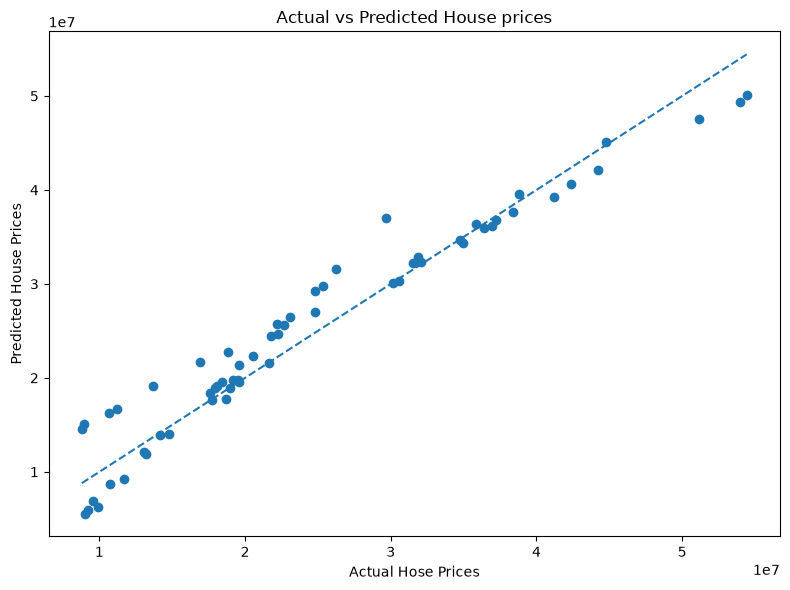

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize = (8,6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle = "--"
)

plt.xlabel("Actual Hose Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House prices")

plt.tight_layout()

plt.savefig("predictions_vs_actual.png", dpi = 300)

plt.show()

In [81]:
results = {
    "Linear Regression" : {
        "MAE" : mean_absolute_error(y_test, y_pred),
        "RMSE" : rmse,
        "R2" : r2
    }
}

print("Baseline model results :: ")
print(results)

Baseline model results :: 
{'Linear Regression': {'MAE': 2188736.343703819, 'RMSE': np.float64(2907633.2073142533), 'R2': 0.9406371185112243}}


In [82]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = PolynomialFeatures(degree = 2, include_bias=False)

x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.fit_transform(x_test)

poly_model = LinearRegression()

poly_model.fit(x_train_poly, y_train)

y_pred_poly = poly_model.predict(x_test_poly)

print("Polynomial Regression training completed!")
print("Predictions generated successfully!")

Polynomial Regression training completed!
Predictions generated successfully!


In [83]:
poly_mae = mean_absolute_error(y_test, y_pred_poly)

poly_mse = mean_squared_error(y_test, y_pred_poly)

poly_rmse = np.sqrt(poly_mse)

poly_r2 = r2_score(y_test, y_pred_poly)

results["Polynomial Regression"] = {
    "MAE" : poly_mae,
    "RMSE" : poly_rmse,
    "R2" : poly_r2
}

print("Polynomial Regression Results")
print("--" * 25)
print("MAE :: ", poly_mae)
print("RMSE :: ", poly_rmse)
print("R2 Score :: ", poly_r2)

Polynomial Regression Results
--------------------------------------------------
MAE ::  714540.7337033902
RMSE ::  896287.7474942617
R2 Score ::  0.9943593305244349


In [84]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(random_state=42)

tree_model.fit(x_train, y_train)

y_pred_tree = tree_model.predict(x_test)

print("Decision Tree training completed!")
print("Predictions generated successfully!")

Decision Tree training completed!
Predictions generated successfully!


In [85]:
tree_mae = mean_absolute_error(y_test, y_pred_tree)

tree_mse = mean_squared_error(y_test, y_pred_tree)

tree_rmse = np.sqrt(tree_mse)

tree_r2 = r2_score(y_test, y_pred_tree)

results["Decision Tree"] = {
    "MAE" : tree_mae,
    "RMSE" : tree_mse,
    "R2" : tree_r2
}

print("Decision Tree Results")
print("--" * 20)
print("MAE :: ", tree_mae)
print("RMSE :: ", tree_rmse)
print("R2 Score :: ", tree_r2)

Decision Tree Results
----------------------------------------
MAE ::  2194416.6666666665
RMSE ::  2864232.2997038257
R2 Score ::  0.9423960573869677


In [86]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
forest_model.fit(x_train, y_train)

# Generate predictions
y_pred_forest = forest_model.predict(x_test)

print("Random Forest training completed!")
print("Predictions generated successfully!")

Random Forest training completed!
Predictions generated successfully!


In [87]:
# Calculate evaluation metrics
forest_mae = mean_absolute_error(y_test, y_pred_forest)

forest_mse = mean_squared_error(y_test, y_pred_forest)

forest_rmse = np.sqrt(forest_mse)

forest_r2 = r2_score(y_test, y_pred_forest)

# Store results
results["Random Forest"] = {
    "MAE": forest_mae,
    "RMSE": forest_rmse,
    "R2": forest_r2
}

print("Random Forest Results")
print("---------------------")
print("MAE:", forest_mae)
print("RMSE:", forest_rmse)
print("R2 Score:", forest_r2)

Random Forest Results
---------------------
MAE: 1453575.8333333333
RMSE: 1932346.9383703244
R2 Score: 0.9737816147909371


In [88]:
import pandas as pd

# Convert results dictionary into DataFrame
comparison_df = pd.DataFrame(results).T

# Display comparison
print(comparison_df)

                                MAE          RMSE        R2
Linear Regression      2.188736e+06  2.907633e+06  0.940637
Polynomial Regression  7.145407e+05  8.962877e+05  0.994359
Decision Tree          2.194417e+06  8.203827e+12  0.942396
Random Forest          1.453576e+06  1.932347e+06  0.973782


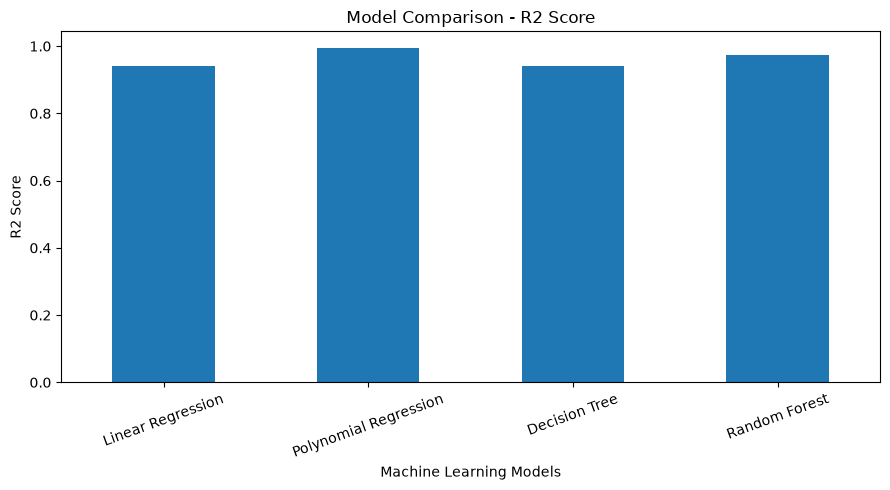

In [89]:
comparison_df[["R2"]].plot(
    kind="bar",
    figsize=(9, 5),
    legend=False,
    title="Model Comparison - R2 Score"
)

plt.ylabel("R2 Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=300)
plt.show()

In [90]:
# Generate predictions on training data

y_train_pred_linear = model.predict(x_train)

y_train_pred_poly = poly_model.predict(x_train_poly)

y_train_pred_tree = tree_model.predict(x_train)

y_train_pred_forest = forest_model.predict(x_train)


# Calculate training R2 scores

train_scores = {
    "Linear Regression": r2_score(y_train, y_train_pred_linear),
    "Polynomial Regression": r2_score(y_train, y_train_pred_poly),
    "Decision Tree": r2_score(y_train, y_train_pred_tree),
    "Random Forest": r2_score(y_train, y_train_pred_forest)
}


# Compare training and testing scores

for model_name in results:
    print("\n", model_name)
    print("Training R2:", train_scores[model_name])
    print("Testing R2:", results[model_name]["R2"])


 Linear Regression
Training R2: 0.957929263255807
Testing R2: 0.9406371185112243

 Polynomial Regression
Training R2: 0.9927196217204526
Testing R2: 0.9943593305244349

 Decision Tree
Training R2: 1.0
Testing R2: 0.9423960573869677

 Random Forest
Training R2: 0.9967930567712775
Testing R2: 0.9737816147909371


In [91]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline

# Define 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Define models
models = {
    "Linear Regression": LinearRegression(),

    "Polynomial Regression": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    ),

    "Decision Tree": DecisionTreeRegressor(random_state=42),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

# Perform cross-validation
for name, algorithm in models.items():

    scores = cross_val_score(
        algorithm,
        x_train,
        y_train,
        cv=cv,
        scoring="r2"
    )

    print("\n", name)
    print("Fold scores:", scores)
    print("Average R2:", scores.mean())
    print("Standard deviation:", scores.std())


 Linear Regression
Fold scores: [0.95307923 0.93862421 0.96161263 0.95619464 0.95493212]
Average R2: 0.9528885659248976
Standard deviation: 0.007677545987612919

 Polynomial Regression
Fold scores: [0.98863572 0.98995585 0.99281794 0.99423285 0.98889453]
Average R2: 0.9909073785457428
Standard deviation: 0.0022282918859150742

 Decision Tree
Fold scores: [0.93752909 0.93259348 0.93664081 0.94843348 0.94534186]
Average R2: 0.9401077432789136
Standard deviation: 0.005862544669072227

 Random Forest
Fold scores: [0.97686067 0.96326565 0.97331733 0.97028465 0.97126454]
Average R2: 0.9709985680128941
Standard deviation: 0.004474803724262043


In [92]:
# Extract feature importance
importance = forest_model.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": importance
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df)

                   Feature  Importance
0                     Area    0.687588
4     Location_City Center    0.155224
5           Location_Rural    0.097460
6          Location_Suburb    0.029165
1                 Bedrooms    0.018998
3                      Age    0.007601
2                Bathrooms    0.001709
9      Property_Type_Villa    0.000885
7  Property_Type_Apartment    0.000757
8      Property_Type_House    0.000613


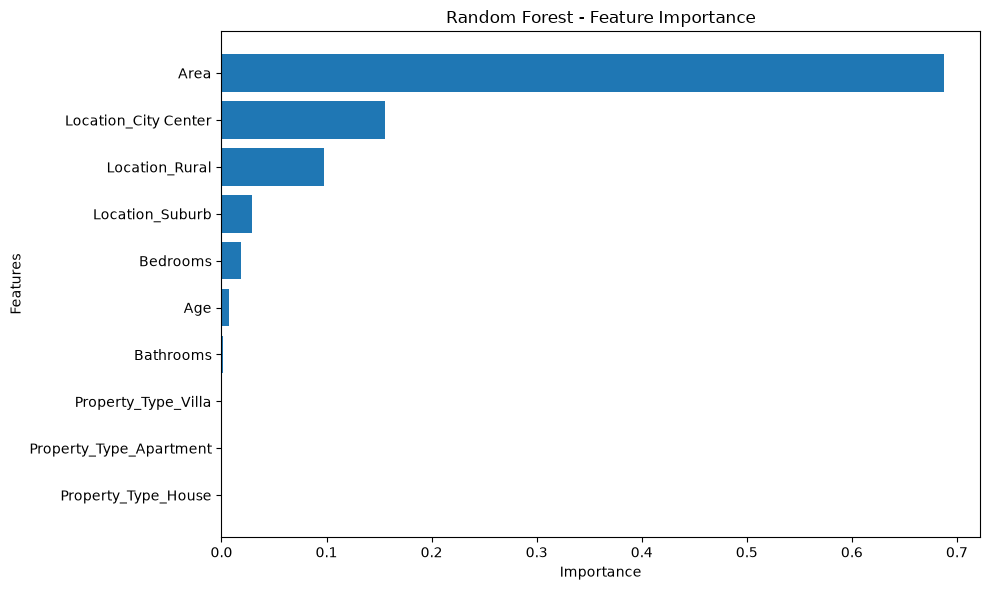

In [93]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Random Forest - Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()